# ML LAB · Бақылаусыз оқыту
K-Means, PCA, клиенттерді сегменттеу, DBSCAN және t-SNE.
new.csv файлын notebook жанына салыңыз немесе интернет арқылы сайттан автоматты жүктеледі.

Rows: 2240 Missing income: 24
     Income  Recency  ...  NumStorePurchases  NumCatalogPurchases
0   58138.0       58  ...                  4                   10
1   46344.0       38  ...                  2                    1
2   71613.0       26  ...                 10                    2
3   26646.0       26  ...                  4                    0
4   58293.0       94  ...                  6                    3
5   62513.0       16  ...                 10                    4
6   55635.0       34  ...                  7                    3
7   33454.0       32  ...                  4                    0
8   30351.0       19  ...                  2                    0
9    5648.0       68  ...                  0                    0
10      NaN       11  ...                  2                    0
11   7500.0       59  ...                  3                    0

[12 rows x 6 columns]


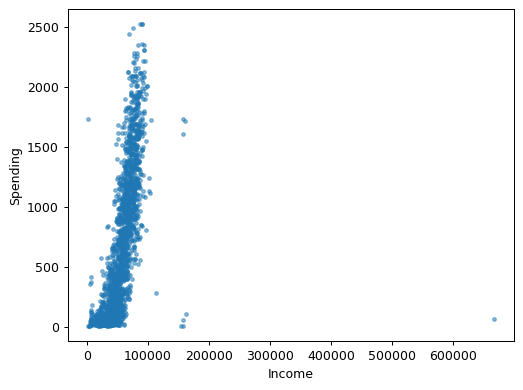

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import make_blobs, make_moons, make_classification
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.cluster import KMeans, DBSCAN, AgglomerativeClustering
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.metrics import silhouette_score, classification_report, confusion_matrix
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import NearestNeighbors
from pathlib import Path
source = 'new.csv' if Path('new.csv').exists() else 'https://svm-lab-kz.kuatakylbek44.chatgpt.site/unsupervised-files/new.csv'
df = pd.read_csv(source)
df['Spending'] = df[['MntWines','MntFruits','MntMeatProducts','MntFishProducts','MntSweetProducts','MntGoldProds']].sum(axis=1)
features = ['Income','Recency','Spending','NumWebPurchases','NumStorePurchases','NumCatalogPurchases']
# ID and Response are not clustering features. Six numerical behaviour features.
raw = SimpleImputer(strategy='median').fit_transform(df[features])
X = StandardScaler().fit_transform(raw)
print('Rows:',len(df),'Missing income:',df.Income.isna().sum())
print(df[features].head(12))
plt.scatter(raw[:,0],raw[:,2],s=8,alpha=.5)
plt.xlabel('Income');plt.ylabel('Spending');plt.show()


Step 1 SSE 12.361897806238343
Step 2 SSE 12.361897806238343


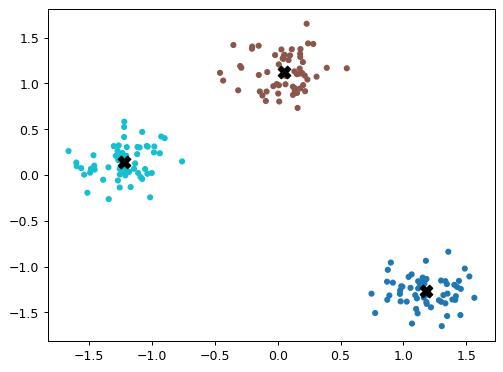

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import make_blobs, make_moons, make_classification
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.cluster import KMeans, DBSCAN, AgglomerativeClustering
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.metrics import silhouette_score, classification_report, confusion_matrix
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import NearestNeighbors
# Educational Lloyd iteration: same initial point indices as the website.
K = 3
X = StandardScaler().fit_transform(make_blobs(n_samples=180,centers=3,random_state=23)[0])
centers = X[[int(i*len(X)/K) for i in range(K)]].copy()
for step in range(30):
    labels = ((X[:,None,:]-centers[None,:,:])**2).sum(axis=2).argmin(axis=1)
    new_centers = np.array([X[labels==i].mean(axis=0) if np.any(labels==i) else centers[i] for i in range(K)])
    print('Step',step+1,'SSE',((X-new_centers[labels])**2).sum())
    done = np.allclose(centers,new_centers)
    centers = new_centers
    if done: break
labels = ((X[:,None,:]-centers[None,:,:])**2).sum(axis=2).argmin(axis=1)
plt.scatter(X[:,0],X[:,1],c=labels,cmap='tab10',s=15)
plt.scatter(centers[:,0],centers[:,1],marker='X',c='black',s=100);plt.show()


   k      inertia  silhouette_sample500
0  2  7637.920340              0.379505
1  3  6600.782467              0.276622
2  4  5769.095147              0.250619
3  5  5257.358559              0.252140
4  6  4688.267329              0.255434
5  7  4293.585346              0.259947
6  8  3989.327373              0.260228


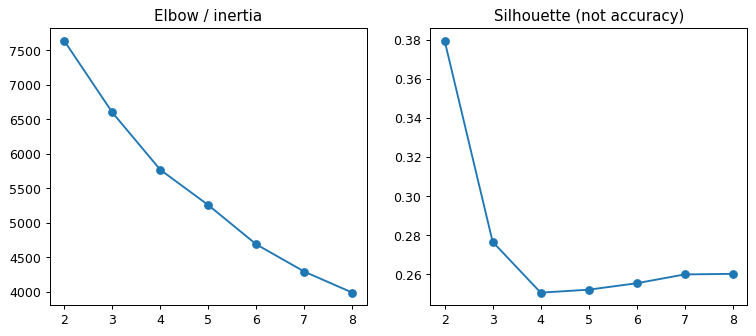

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import make_blobs, make_moons, make_classification
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.cluster import KMeans, DBSCAN, AgglomerativeClustering
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.metrics import silhouette_score, classification_report, confusion_matrix
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import NearestNeighbors
from pathlib import Path
source = 'new.csv' if Path('new.csv').exists() else 'https://svm-lab-kz.kuatakylbek44.chatgpt.site/unsupervised-files/new.csv'
df = pd.read_csv(source)
df['Spending'] = df[['MntWines','MntFruits','MntMeatProducts','MntFishProducts','MntSweetProducts','MntGoldProds']].sum(axis=1)
features = ['Income','Recency','Spending','NumWebPurchases','NumStorePurchases','NumCatalogPurchases']
# ID and Response are not clustering features. Six numerical behaviour features.
raw = SimpleImputer(strategy='median').fit_transform(df[features])
X = StandardScaler().fit_transform(raw)
# Compare k using the same six standardized features.
results=[]
for k in range(2,9):
    m=KMeans(n_clusters=k,n_init=10,random_state=22).fit(X)
    score=silhouette_score(X,m.labels_,sample_size=500,random_state=42)
    results.append([k,m.inertia_,score])
r=pd.DataFrame(results,columns=['k','inertia','silhouette_sample500'])
print(r)
fig,ax=plt.subplots(1,2,figsize=(10,4))
ax[0].plot(r.k,r.inertia,'o-');ax[0].set_title('Elbow / inertia')
ax[1].plot(r.k,r.silhouette_sample500,'o-');ax[1].set_title('Silhouette (not accuracy)')
plt.show()


Customers / features: (2240, 6)
Components: 2 StandardScaler: True
Retained variance: 70.7 %
Each PC: [0.54001588 0.16701778]


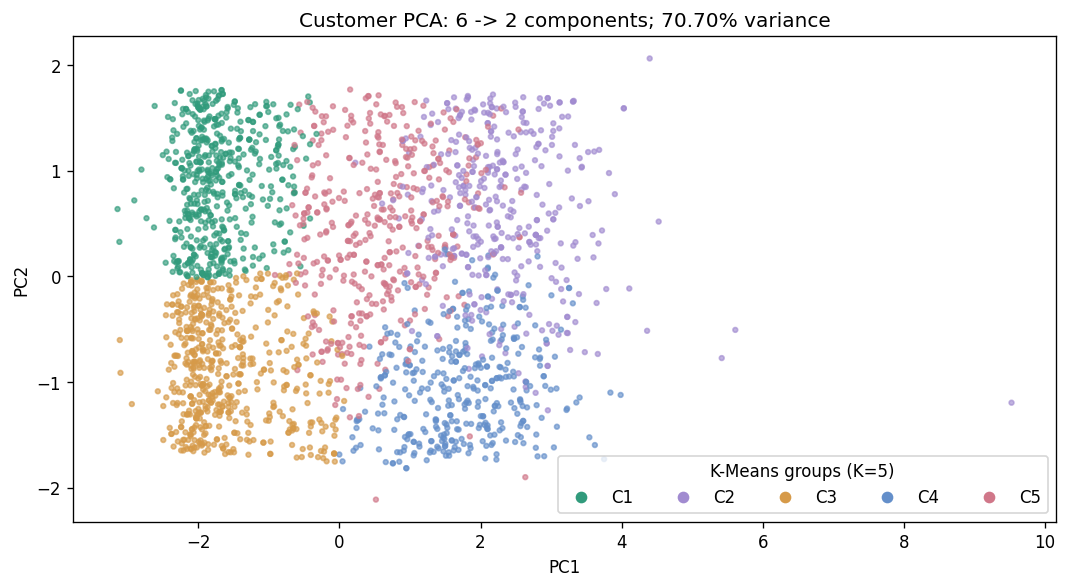

In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from matplotlib.colors import ListedColormap
from matplotlib.lines import Line2D
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA

# Same 2240 customers and six features as the customer clustering page.
source = 'new.csv' if Path('new.csv').exists() else 'https://svm-lab-kz.kuatakylbek44.chatgpt.site/unsupervised-files/new.csv'
df = pd.read_csv(source)
work = df.copy()
work['Spending'] = work[['MntWines','MntFruits','MntMeatProducts','MntFishProducts','MntSweetProducts','MntGoldProds']].sum(axis=1)
features = ['Income','Recency','Spending','NumWebPurchases','NumStorePurchases','NumCatalogPurchases']
raw = SimpleImputer(strategy='median').fit_transform(work[features])
scale=True
X = StandardScaler().fit_transform(raw) if scale else raw
components=2
pca = PCA(n_components=components)
Z = pca.fit_transform(X)
# Colour groups use the same six-dimensional input, never the PCA projection.
labels = KMeans(n_clusters=5, n_init=10, random_state=22).fit_predict(X)
print('Customers / features:', X.shape)
print('Components:', components, 'StandardScaler:', scale)
print('Retained variance:', round(pca.explained_variance_ratio_.sum()*100,2), '%')
print('Each PC:', pca.explained_variance_ratio_)
colours = ['#319b7c','#a18bd0','#d69a49','#648fca','#d07789']
plt.figure(figsize=(9,5))
plt.scatter(Z[:,0], Z[:,1] if components>1 else np.zeros(len(Z)),
            c=labels, cmap=ListedColormap(colours), vmin=0, vmax=4, s=8, alpha=.65)
plt.xlabel('PC1'); plt.ylabel('PC2' if components>1 else '0')
plt.title(f'Customer PCA: 6 -> {components} components; {pca.explained_variance_ratio_.sum()*100:.2f}% variance')
plt.legend(handles=[Line2D([],[],marker='o',linestyle='',color=colours[i],label=f'C{i+1}')
                    for i in range(5)], title='K-Means groups (K=5)', ncol=5, loc='best')
plt.tight_layout(); plt.show()
# Colours are exploratory K-Means groups, not true customer classes.
# PCA does not cluster. With 3-6 components the plot still shows only PC1 and PC2.
# Retained variance is not prediction accuracy; all original rows are kept.


PCA variance: 0.7070336598893938
               Income         Recency  ... NumStorePurchases NumCatalogPurchases     
                 mean size       mean  ...              size                mean size
cluster                                ...                                           
0        34841.183495  515  74.174757  ...               515            0.543689  515
1        78200.720588  374  66.098930  ...               374            6.890374  374
2        36099.385305  558  22.987455  ...               558            0.639785  558
3        69517.890541  370  19.659459  ...               370            4.535135  370
4        56637.611111  423  63.789598  ...               423            2.531915  423

[5 rows x 12 columns]


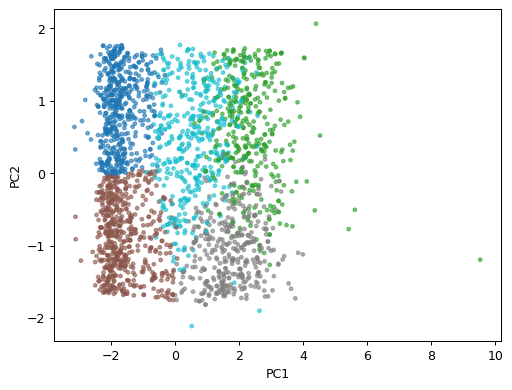

In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import make_blobs, make_moons, make_classification
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.cluster import KMeans, DBSCAN, AgglomerativeClustering
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.metrics import silhouette_score, classification_report, confusion_matrix
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import NearestNeighbors
from pathlib import Path
source = 'new.csv' if Path('new.csv').exists() else 'https://svm-lab-kz.kuatakylbek44.chatgpt.site/unsupervised-files/new.csv'
df = pd.read_csv(source)
df['Spending'] = df[['MntWines','MntFruits','MntMeatProducts','MntFishProducts','MntSweetProducts','MntGoldProds']].sum(axis=1)
features = ['Income','Recency','Spending','NumWebPurchases','NumStorePurchases','NumCatalogPurchases']
# ID and Response are not clustering features. Six numerical behaviour features.
raw = SimpleImputer(strategy='median').fit_transform(df[features])
X = StandardScaler().fit_transform(raw)
K=5
scale=True
A=X if scale else raw
model=KMeans(n_clusters=K,n_init=10,random_state=22)
labels=model.fit_predict(A)
projection=PCA(n_components=2)
Z=projection.fit_transform(A)
print('PCA variance:',projection.explained_variance_ratio_.sum())
print(pd.DataFrame(raw,columns=features).assign(cluster=labels).groupby('cluster').agg(['mean','size']))
plt.scatter(Z[:,0],Z[:,1],c=labels,cmap='tab10',s=8,alpha=.6)
plt.xlabel('PC1');plt.ylabel('PC2');plt.show()
# KMeans uses SIX features; PCA is only the two-dimensional display.
# These are exploratory groups, not known classes or prediction accuracy.


DBSCAN clusters: 2 Noise: 0


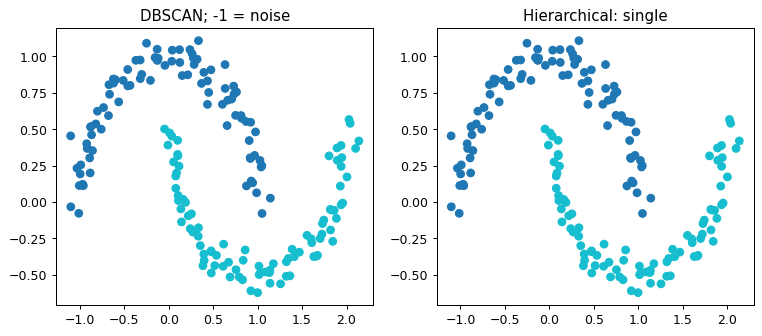

In [6]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import make_blobs, make_moons, make_classification
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.cluster import KMeans, DBSCAN, AgglomerativeClustering
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.metrics import silhouette_score, classification_report, confusion_matrix
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import NearestNeighbors
X,_=make_moons(n_samples=180,noise=.07,random_state=23)
eps=.2
min_samples=5
labels=DBSCAN(eps=eps,min_samples=min_samples).fit_predict(X)
print('DBSCAN clusters:',len(set(labels)-{-1}),'Noise:',sum(labels==-1))
fig,ax=plt.subplots(1,2,figsize=(10,4))
ax[0].scatter(X[:,0],X[:,1],c=labels,cmap='tab10');ax[0].set_title('DBSCAN; -1 = noise')
K=2
linkage='single'
hier=AgglomerativeClustering(n_clusters=K,linkage=linkage).fit_predict(X)
ax[1].scatter(X[:,0],X[:,1],c=hier,cmap='tab10');ax[1].set_title('Hierarchical: '+linkage)
plt.show()


Customers / features: (2240, 6)
Missing Income filled with median: 24
PCA retained variance: 70.7 %
K-Means colour groups (C1-C5): [515 374 558 370 423]


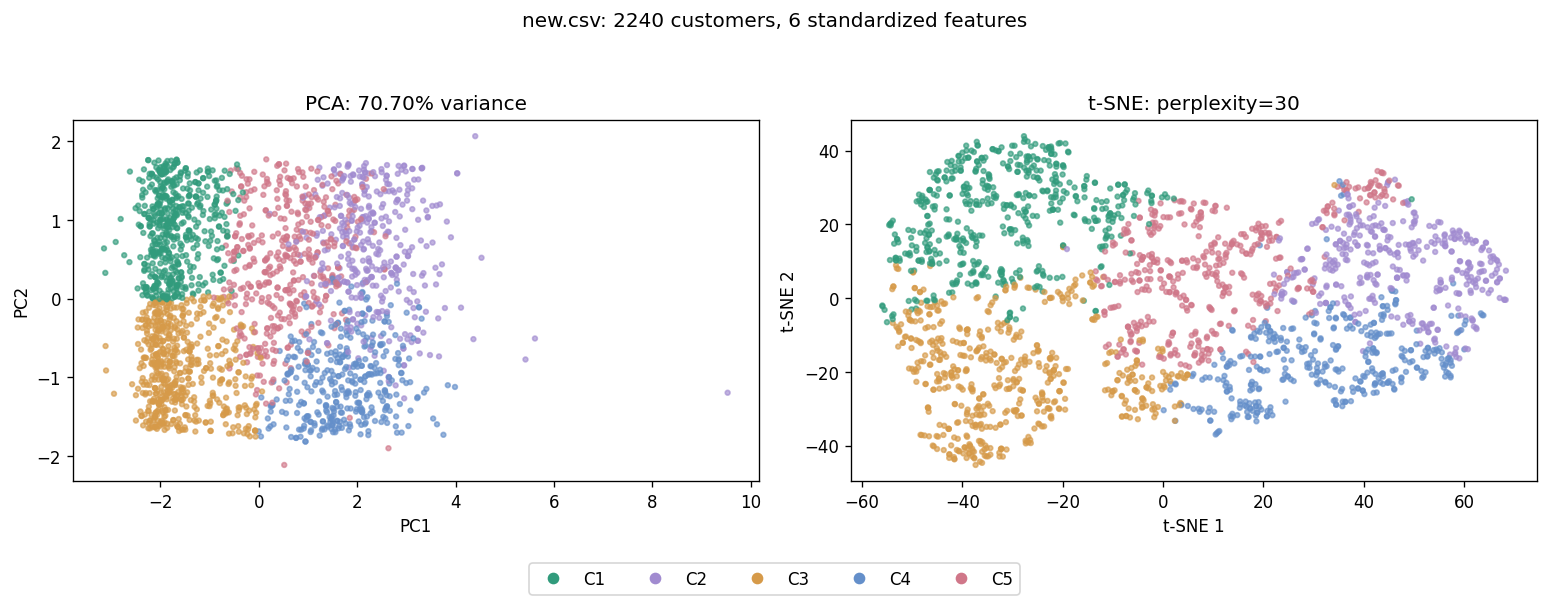

In [7]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from matplotlib.colors import ListedColormap
from matplotlib.lines import Line2D
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE

# Same customer dataset and six features as pages 1, 3 and 5.
source = 'new.csv' if Path('new.csv').exists() else 'https://svm-lab-kz.kuatakylbek44.chatgpt.site/unsupervised-files/new.csv'
df = pd.read_csv(source)
work = df.copy()
work['Spending'] = work[['MntWines','MntFruits','MntMeatProducts','MntFishProducts','MntSweetProducts','MntGoldProds']].sum(axis=1)
features = ['Income','Recency','Spending','NumWebPurchases','NumStorePurchases','NumCatalogPurchases']
raw = SimpleImputer(strategy='median').fit_transform(work[features])
X = StandardScaler().fit_transform(raw)
# All 2240 customers are kept. No ID, Response or known class labels.
K = 5
labels = KMeans(n_clusters=K, n_init=10, random_state=22).fit_predict(X)
pca = PCA(n_components=2)
P = pca.fit_transform(X)
perplexity=30
Z = TSNE(n_components=2, perplexity=perplexity, random_state=42,
         init='pca', learning_rate='auto', max_iter=1000).fit_transform(X)
print('Customers / features:', X.shape)
print('Missing Income filled with median:', df['Income'].isna().sum())
print('PCA retained variance:', round(pca.explained_variance_ratio_.sum()*100, 2), '%')
print('K-Means colour groups (C1-C5):', np.bincount(labels))
colours = ['#319b7c','#a18bd0','#d69a49','#648fca','#d07789']
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, points, title, names in zip(axes, [P, Z],
        [f'PCA: {pca.explained_variance_ratio_.sum()*100:.2f}% variance',
         f't-SNE: perplexity={perplexity}'], [('PC1','PC2'),('t-SNE 1','t-SNE 2')]):
    ax.scatter(points[:,0], points[:,1], c=labels, cmap=ListedColormap(colours),
               vmin=0, vmax=K-1, s=8, alpha=.65)
    ax.set(title=title, xlabel=names[0], ylabel=names[1])
fig.suptitle('new.csv: 2240 customers, 6 standardized features')
fig.legend(handles=[Line2D([],[],marker='o',linestyle='',color=colours[i],label=f'C{i+1}')
                    for i in range(K)], loc='lower center', ncol=K)
fig.tight_layout(rect=[0,.08,1,.94])
plt.show()
# Colours are K-Means groups in SIX dimensions, not known customer classes.
# PCA and t-SNE only visualize; neither assigns these cluster labels.
# Interpret local neighbours, not global t-SNE distances or group areas.
